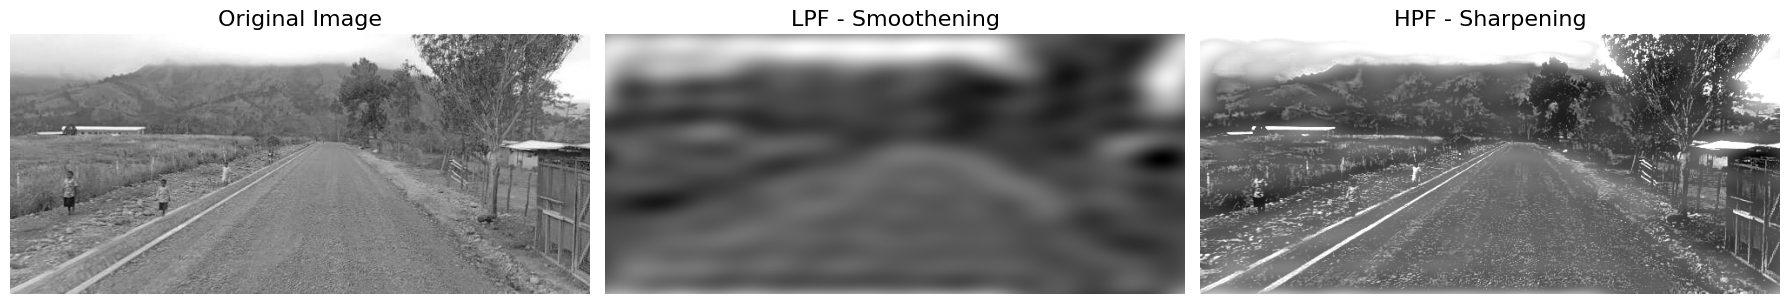

In [7]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread("images.jpeg", cv2.IMREAD_GRAYSCALE)

F = np.fft.fftshift(np.fft.fft2(img))
M, N = img.shape

u, v = np.meshgrid(np.arange(N)-N//2, np.arange(M)-M//2)
D = np.sqrt(u**2 + v**2)

LPF = D < 10
HPF = D >= 10

smooth = np.abs(np.fft.ifft2(np.fft.ifftshift(F * LPF)))
high_pass = np.abs(np.fft.ifft2(np.fft.ifftshift(F * HPF)))
sharp = np.clip(img.astype(float) + high_pass, 0, 255)

plt.figure(figsize=(18, 7))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title('Original Image', fontsize=16)
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(smooth, cmap='gray')
plt.title('LPF - Smoothening', fontsize=16)
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(sharp, cmap='gray')
plt.title('HPF - Sharpening', fontsize=16)
plt.axis('off')

plt.tight_layout()
plt.show()